### Imports

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from scipy import stats

### Funções

In [25]:
def implot(img, img_filt, filt_name, kernelsize):
  plt.subplot(1, 2, 1)
  plt.imshow(img, cmap='gray')
  plt.title('Original')
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.imshow(img_filt, cmap='gray')
  plt.title(f'Filtro {filt_name} {kernelsize}')
  plt.axis('off')

  plt.show()

def apply_filter_manual(img, filter_type, size=3):
    pad = size // 2
    # Aplica padding espelhado para tratar as bordas de forma realista
    img_padded = np.pad(img, pad, mode='edge')
    h, w = img.shape
    img_out = np.zeros_like(img)

    for i in range(h):
        for j in range(w):
            # Extrai a vizinhança (janela/kernel)
            window = img_padded[i:i+size, j:j+size]

            if filter_type == 'media':
                img_out[i, j] = np.mean(window)
            elif filter_type == 'mediana':
                img_out[i, j] = np.median(window)
            elif filter_type == 'moda':
                # stats.mode retorna o valor mais comum e sua contagem
                mode_val = stats.mode(window, axis=None, keepdims=False)[0]
                img_out[i, j] = mode_val
            elif filter_type == 'maxima':
                img_out[i, j] = np.max(window)

    return img_out

###Aplicação dos Filtros

In [28]:
img_original = data.camera()

#### Filtro de Média

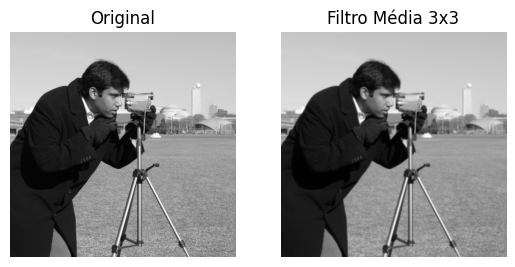

In [27]:
img_media = apply_filter_manual(img_original, 'media', size=3)
implot(img_original, img_media, 'Média', '3x3')

#### Filtro de Mediana

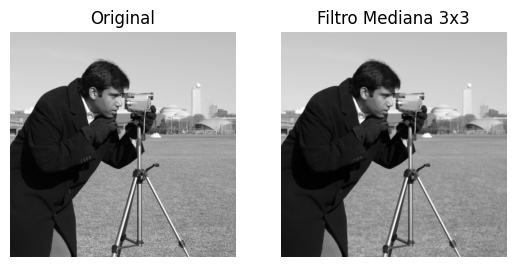

In [21]:
img_mediana = apply_filter_manual(img_original, 'mediana', size=3)
implot(img_original, img_mediana, 'Mediana', '3x3')

#### Filtro de Moda

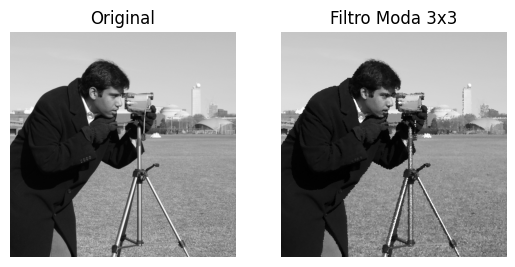

In [22]:
img_moda = apply_filter_manual(img_original, 'moda', size=3)
implot(img_original, img_moda, 'Moda', '3x3')

#### Filtro de Máxima

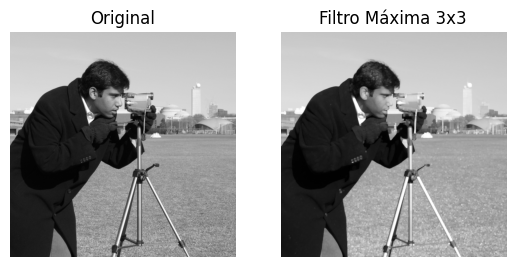

In [23]:
img_maxima = apply_filter_manual(img_original, 'maxima', size=3)
implot(img_original, img_maxima, 'Máxima', '3x3')